# Dar_011 — All P1 research rows: coverage, blocked evidence and next analysis
This notebook reconciles **every `P1-*` row** in the research CSV with the local notebooks,
actual selected products and unresolved science/access requirements. It is a readiness
audit, **not fabricated EDA for missing data**. Original CSV progress means original-project
progress and is retained; local implementation/evidence is recorded separately.

In [1]:
from pathlib import Path
import sys, json, io, re, zipfile
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p/'outline.md').is_file() and (p/'notebooks').is_dir())
sys.path[:0] = [str(ROOT/'darrel stuff/EDA'),str(ROOT)]
DATA = ROOT/'darrel stuff/data'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from environment_workflow import LocalRun as Run, latest_completed_run
from notebooks.shared.inspection import verify_run, check_input
from research_p1_readers import (pilot_files, pin_source, read_pds4, pds4_chunks,
    pds4_definition, pds4_image, dose_profiles, pds3_number)
import research_p1_readers
def savefig(run, fig, name):
    fig.savefig(run.path(name+'.png'),dpi=140,bbox_inches='tight')
    display(fig); plt.close(fig)
def save_findings(run, findings):
    run.path('findings.json').write_text(json.dumps(findings,indent=2,default=str),encoding='utf-8')
    display(Markdown('**Executed findings**')); display(findings)
def pin(run, path): return pin_source(run, path)
def short(region): return region.split('_',2)[-1].replace('_',' ')

## Status rules
- `bounded_eda` means an implemented bounded-data analysis, not a whole-archive completion
  or a Stage 3 requirement pass.
- `partial_scope` means useful numeric EDA exists but the originally proposed site/product,
  response, unit or coverage comparison is still unsupported.
- D21 ChaSTE and D23 ILSA remain login-gated: no invented columns, temperatures or waveforms.
- Missing project M-rows require real project/test records or explicitly modeled outputs.
- C01 is background context, not a time-varying statistical dataset.

,dataset_id,group,local_status,notebook,remaining_requirement
0,D01,Temperature & Thermal,bounded_eda,Dar_001_temperature_local_time.ipynb,Phase/local-time coverage and fixed-cohort sen...
1,D04,Temperature & Thermal,bounded_eda,Dar_002_temperature_environment_relationships....,"Sky solid angle and thermal association, not c..."
2,D20,Temperature & Thermal,partial_scope,Dar_004_research_thermal.ipynb,RDR quality/coverage diagnostics; polar-site/d...
3,D21,Temperature & Thermal,login_required,None,"Authorised ChaSTE release, calibration, depth/..."
4,D28,Temperature & Thermal,bounded_eda,Dar_004_research_thermal.ipynb,"Historical Apollo sensor/time/depth context, n..."
5,D38,Temperature & Thermal,bounded_eda,Dar_004_research_thermal.ipynb,"Coarse polar cumulative context, not site-leve..."
6,M01,Temperature & Thermal,project_data_missing,None,Requires real tests or explicitly labeled mode...
7,D07,Radiation,partial_scope,Dar_005_research_radiation.ipynb,SEC counters available; LET/event spectra requ...
8,D08,Radiation,partial_scope,Dar_005_research_radiation.ipynb,Two pilot days have no strict accepted average...
9,D31,Radiation,bounded_eda,Dar_005_research_radiation.ipynb,Published scenarios; project transport/approve...


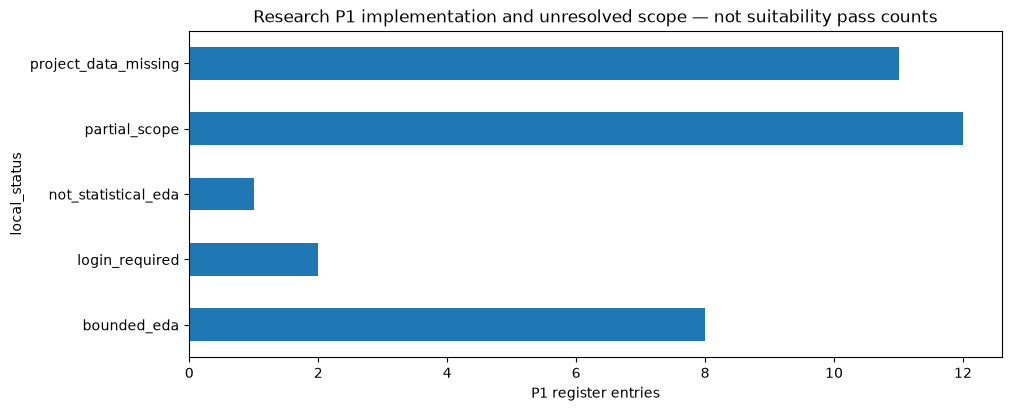

**Executed findings**

{'P1_rows': 34,
 'P1_external_datasets': 22,
 'local_status_counts': {'bounded_eda': 8,
  'login_required': 2,
  'not_statistical_eda': 1,
  'partial_scope': 12,
  'project_data_missing': 11},
 'gated_datasets': ['D21', 'D23'],
 'mission_equipment_data': 'not supplied; mandatory requirements remain Unknown',
 'other_priority_rows': 'P2/P3 intentionally outside this request; Dar_003 Earth core EDA retained separately'}

Completed: C:\Darrel\Self-Projects\1 group proj\NASA-Space-Apps-Challenge-2026\darrel stuff\data\processed\analysis\dar_011_research_readiness\20261106T094421920934Z_0dd1bd


In [2]:
import csv
REGISTER=ROOT/'darrel stuff/research/environmental_data.csv'
mapping={
 'D01':('Dar_001_temperature_local_time.ipynb','bounded_eda','Phase/local-time coverage and fixed-cohort sensitivity; not dated extremes'),
 'D02':('Dar_002_temperature_environment_relationships.ipynb','bounded_eda','Mean solar/PSR context; dated terrain shadows still missing'),
 'D03':('Dar_002_temperature_environment_relationships.ipynb','bounded_eda','Mean Earth visibility, not a radio link/outage history'),
 'D04':('Dar_002_temperature_environment_relationships.ipynb','bounded_eda','Sky solid angle and thermal association, not cooling capacity'),
 'D05':('Dar_006_research_terrain_support.ipynb','partial_scope','Central bounded patches only; no new whole-region terrain-view EDA'),
 'D06':('Dar_006_research_terrain_support.ipynb','partial_scope','Quality-band sensitivity; unfinished slope-error raster excluded'),
 'D07':('Dar_005_research_radiation.ipynb','partial_scope','SEC counters available; LET/event spectra require another selected product'),
 'D08':('Dar_005_research_radiation.ipynb','partial_scope','Two pilot days have no strict accepted averages; retained ERR DQFs are not silently relaxed'),
 'D13':('Dar_007_research_seismic.ipynb','bounded_eda','Two distinct catalogs; no polar recurrence estimate'),
 'D14':('Dar_007_research_seismic.ipynb','partial_scope','Actual MHZ plus ATT; instrument response and event windows still missing'),
 'D15':('Dar_008_research_imagery_change.ipynb','partial_scope','CDR pixel/quality EDA; calibrated map-projected site overlap unestablished'),
 'D16':('Dar_009_research_lcross_spectra.ipynb','partial_scope','Calibrated pre-impact spectra only; no post-impact/species fit'),
 'D19':('Dar_010_research_spice_geometry.ipynb','partial_scope','Reference-sphere geometry; terrain horizons and mission profile missing'),
 'D20':('Dar_004_research_thermal.ipynb','partial_scope','RDR quality/coverage diagnostics; polar-site/date/strict-quality comparison unresolved'),
 'D21':(None,'login_required','Authorised ChaSTE release, calibration, depth/deployment and heater-state metadata needed'),
 'D23':(None,'login_required','Authorised ILSA release, response, timing and disturbance/activity metadata needed'),
 'D26':('Dar_006_research_terrain_support.ipynb','partial_scope','Equatorial tiles do not overlap the seven polar study regions'),
 'D27':('Dar_008_research_imagery_change.ipynb','partial_scope','North-polar pilot; physical unit and south-polar co-registration unresolved'),
 'D28':('Dar_004_research_thermal.ipynb','bounded_eda','Historical Apollo sensor/time/depth context, not polar seasonal response'),
 'D31':('Dar_005_research_radiation.ipynb','bounded_eda','Published scenarios; project transport/approved limits still required'),
 'D33':('Dar_008_research_imagery_change.ipynb','partial_scope','Crater catalog EDA; image-time brackets and search-effort normalization missing'),
 'D38':('Dar_004_research_thermal.ipynb','bounded_eda','Coarse polar cumulative context, not site-level mission extremes'),
}
with Run(ROOT,'analysis/dar_011_research_readiness',{'scope':'every P1 row in environmental_data.csv'},'Moon/Environmental_Context/Dar_011_research_p1_coverage_gaps.ipynb') as run:
    run.input(REGISTER);rows=[]
    for row in csv.DictReader(REGISTER.open(encoding='utf-8-sig')):
        if not row['Priority ID'].startswith('P1-'):continue
        key=row['Priority ID'].split()[0].split('-')[1]
        if key.startswith('D'):
            if key not in mapping:raise ValueError(f'Unmapped P1 dataset {key}')
            notebook,status,hold=mapping[key]
        elif key.startswith('M'):
            notebook,status,hold=None,'project_data_missing',row['Limitations']
        elif key=='C01':notebook,status,hold=None,'not_statistical_eda',row['Limitations']
        else:raise ValueError(f'Unknown register row {key}')
        code_cells=0;error_cells=0;latest_run=None
        if notebook:
            path=ROOT/'darrel stuff/EDA/Moon'/notebook;run.input(path);n=json.loads(path.read_text(encoding='utf-8'))
            code=[c for c in n['cells'] if c['cell_type']=='code'];code_cells=sum(c.get('execution_count') is not None for c in code)
            error_cells=sum(o.get('output_type')=='error' for c in code for o in c.get('outputs',[]))
            if code_cells!=len(code) or error_cells:status='implementation_not_verified'
        rows.append({'priority_id':row['Priority ID'],'dataset_id':key,'dataset':row['Dataset'],'group':row['Environmental Group'],
            'source':row['Source'],'original_csv_status':row['EDA Status'],'local_status':status,'notebook':notebook,
            'executed_code_cells':code_cells,'error_outputs':error_cells,'remaining_requirement':hold})
    table=pd.DataFrame(rows)
    assert set(table.loc[table.dataset_id.str.startswith('D'),'dataset_id'])==set(mapping)
    table.to_csv(run.path('all_p1_research_coverage.csv'),index=False)
    display(table[['dataset_id','group','local_status','notebook','remaining_requirement']])
    counts=table.groupby('local_status').size();fig,ax=plt.subplots(figsize=(10,4),layout='constrained')
    counts.plot.barh(ax=ax);ax.set(xlabel='P1 register entries',title='Research P1 implementation and unresolved scope — not suitability pass counts')
    savefig(run,fig,'p1_coverage_and_holds')
    save_findings(run,{'P1_rows':len(table),'P1_external_datasets':len(mapping),'local_status_counts':counts.to_dict(),
        'gated_datasets':['D21','D23'],'mission_equipment_data':'not supplied; mandatory requirements remain Unknown',
        'other_priority_rows':'P2/P3 intentionally outside this request; Dar_003 Earth core EDA retained separately'})
OUT=run.directory;print('Completed:',OUT)

## Stage 3 handoff
Read the per-row holds before selecting algorithm inputs. Environmental correlations do
not become equipment tolerances or weights automatically. Use actual mission/equipment
profiles to establish applicable hard constraints and keep missing evidence Unknown.
Only after mandatory requirements are satisfied should preference scoring be considered.
This notebook makes no missing-data simulation and no claim that all P1 questions are solved.